## **Random Forest**

### **Solving a red-wine Classifiaction Problem with Random Forest Classifier**

- `quality`:  Integer score(Typically from 3 to 8) based on human taste test<br>
we'll convert this into a binary classification(good vs not-good wine)

### **Import Data**

In [1]:
import pandas as pd 

In [2]:
data = pd.read_csv(r'c:\Users\LENOVO\Downloads\winequality-red.csv')

In [3]:
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
data.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [5]:
data.shape

(1599, 12)

In [6]:
data.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

## **Check the unique values**

In [7]:
data['quality'].unique()

array([5, 6, 7, 4, 8, 3])

## **Create a binary classification problem: Good(7-10) vs Not Good(<=6)**

In [8]:
data['target'] = (data['quality'] >= 7).astype(int)

In [9]:
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [10]:
data =data.drop('quality',axis=1)

In [11]:
data['target'].value_counts()

target
0    1382
1     217
Name: count, dtype: int64

## **Split into train & test**

In [12]:
x = data.drop('target',axis=1)
y = data['target']

In [13]:
x.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


In [14]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
x_train , x_test, y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42,stratify=y)

In [17]:
x_train.shape,x_test.shape

((1119, 11), (480, 11))

## **Build a basic Random forest model**

In [18]:
from sklearn.ensemble import RandomForestClassifier

In [19]:
rf = RandomForestClassifier(
    n_estimators=100,  #number of trees
    max_depth=None, # no limit of depth
    max_features='sqrt', #sqrt(p) features at each split
    random_state=42,
    oob_score=True # Enable Out-of-Bag score
    )

In [20]:
rf.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## **Check Out-of-Bag score (an internall cross-validation metric)**

In [21]:
print('OOB Score: {0:0.4f}'.format(rf.oob_score_))

OOB Score: 0.8937


In [22]:
## Indicates generalization ability without external Cross-Validation metric.

## **Make Predictions**

In [23]:
y_pred = rf.predict(x_test)
y_proba = rf.predict_proba(x_test)[:,1] # Probabilities for ROC AUC

## **Evaluate the model**

In [24]:
from sklearn.metrics import classification_report

In [25]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.93      0.99      0.96       415
           1       0.92      0.51      0.65        65

    accuracy                           0.93       480
   macro avg       0.92      0.75      0.81       480
weighted avg       0.93      0.93      0.92       480



In [26]:
from sklearn.metrics import roc_auc_score

In [27]:
print("ROC-AUC:",roc_auc_score(y_test,y_proba))

ROC-AUC: 0.9396292863762743


## **Confusion Matrix**

In [28]:
from sklearn.metrics import confusion_matrix

In [29]:
cm = confusion_matrix(y_test,y_pred)
print('confusion_matrix\n',cm)

confusion_matrix
 [[412   3]
 [ 32  33]]


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

Text(0.5, 1.0, 'Confusion Matrix')

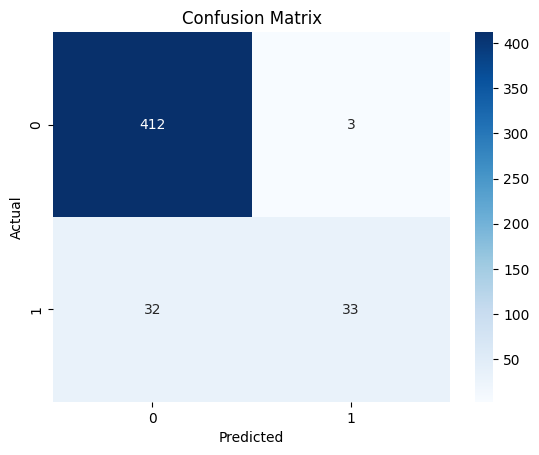

In [31]:
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix')

**Summary**<br>
`precision`: 0.92 , when model predicts class 1 , it is correct 92% (low false negative)<br>
`recall`: 0.51 , Model only finds 51% of all actual class wines (low true negative)<br>
`F1-Score`: 0.65 , Harmonic mean of presion and racall rate

In [32]:
#poor recall score 
# solution: Improved model using class_weight = balanced

In [33]:
rf_balanced = RandomForestClassifier(n_estimators=100,random_state=42,class_weight='balanced')
rf_balanced.fit(x_train,y_train)
y_pred_balanced = rf_balanced.predict(x_test)
print('Classification Report(Balanced Class Weights):')
print(classification_report(y_test,y_pred_balanced))

Classification Report(Balanced Class Weights):
              precision    recall  f1-score   support

           0       0.93      0.99      0.96       415
           1       0.89      0.51      0.65        65

    accuracy                           0.93       480
   macro avg       0.91      0.75      0.80       480
weighted avg       0.92      0.93      0.92       480



## **Confusion Matrix**

In [34]:
cm1 = confusion_matrix(y_test,y_pred_balanced)

Text(0.5, 1.0, 'Confusion Matrix')

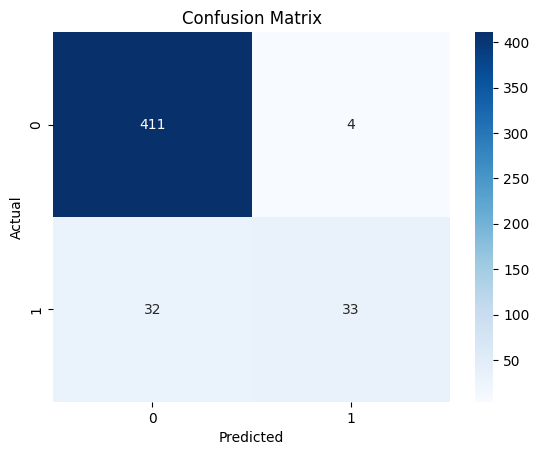

In [35]:
sns.heatmap(cm1,annot=True,fmt='d',cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix')

In [36]:
print(f"cm_before\n {cm}\ncm_after\n {cm1}")

cm_before
 [[412   3]
 [ 32  33]]
cm_after
 [[411   4]
 [ 32  33]]


**Observation**<br>
Unfortunately , this method didn't work, it shows same value of Recall after class balance.<br>
When the class imbalance is extreme,simply reweighting might not be enough.<br>
So What we can do ?<br>
Let's explore another easy but effective solution: Threshold  tuning or resampling techniques like SMOTE

### **Threshold Tunning (Recommended Next)**<br>
Keep the existing model,but adjusted the decsion threshold.<br>
Goal: increase recall ,even if precision drops a bit

### **Get predicted probabilities for class 1**

In [37]:
from sklearn.metrics import precision_recall_curve
y_probs = rf.predict_proba(x_test)[:,1]

### **Plot precision-recall curve to choose a better threshold**

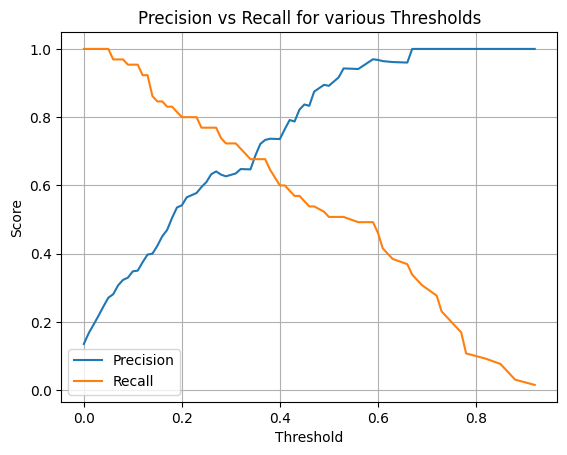

In [38]:
import matplotlib.pyplot as plt
precision , recall ,threshold = precision_recall_curve(y_test,y_probs)
plt.plot(threshold,precision[:-1],label = 'Precision')
plt.plot(threshold,recall[:-1],label = 'Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision vs Recall for various Thresholds')
plt.legend()
plt.grid()
plt.show()

**Observation**:
change the threshold values at ~0.30

In [39]:
y_pred_tresh = (y_probs >0.31).astype(int)
print('New Classification Report (Threshold = 0.3):')
print(classification_report(y_test,y_pred_tresh))

New Classification Report (Threshold = 0.3):
              precision    recall  f1-score   support

           0       0.95      0.94      0.95       415
           1       0.65      0.71      0.68        65

    accuracy                           0.91       480
   macro avg       0.80      0.82      0.81       480
weighted avg       0.91      0.91      0.91       480



In [40]:
# This technique of lowering threshhold worked.

### **Other alternative Technique**<br>
SMOTE (Synthetic Minority Over_smapling Technique)<br>
`how it works` <br>
it picks a sample from class 1 <br>
find few of it's neartest neighbours(also from class 1)<br>
create a new synthetic point between them.<br>
so if our class 1 has only 217 real samples, SMOTE might create 200-300 more similer but slightly varied 

## **Feature Importance Visualization**

In [41]:
importances = rf.feature_importances_
feat_importancesx= pd.Series(importances,index=x.columns).sort_values(ascending = False)

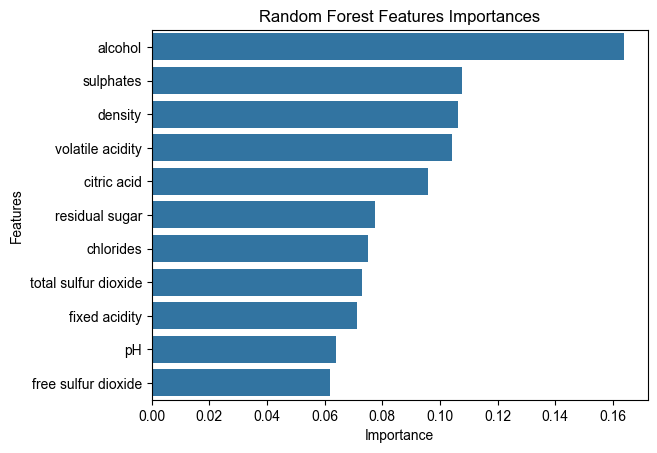

In [42]:
sns.barplot(x=feat_importancesx.values,y = feat_importancesx.index)
plt.title('Random Forest Features Importances')
sns.set_style('darkgrid')
plt.ylabel('Features')
plt.xlabel('Importance')
plt.show()

In [43]:
## Identify top predictors: (eg., alcohol content,sulphates,density,volatile acidity)

## **Hyperparameter Tunning with GridSearchCV**

In [44]:
from sklearn.model_selection import GridSearchCV

In [45]:
param_grid = {
    'n_estimators': [100,200],
    'max_depth':[None,10,20],
    'min_samples_split':[2,5],
}

In [46]:
grid = GridSearchCV(RandomForestClassifier(random_state=42),param_grid,
                    cv=3 ,scoring='roc_auc',n_jobs=-1)
grid.fit(x_train,y_train)
print('Best Params:',grid.best_params_)
print('Best AUC (CV):',grid.best_score_)

Best Params: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Best AUC (CV): 0.8687450083008031


### **SMOTE & Resampling Techniques**

In [47]:
## Why need resampling
print(data['target'].value_counts())

target
0    1382
1     217
Name: count, dtype: int64


**Problem**:<br>
This is called class imbalance - the model might ignore minority  class(1=*Good Wine* ) and still get high accuracy.

In [48]:
## SMOTE in python
data

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,target
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,0
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,0
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,0
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,0
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,0
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,0
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,0
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,0


In [49]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

In [50]:
## Features & Target 


## Define Target and Features
x = data.drop('target',axis=1) # No 'quality' column in current dataset 
y = data['target']

# Train_test Split
x_train,x_test,y_train,y_test = train_test_split(x,y,stratify=y,random_state=42)

## Apply SMOTE to training data
sm = SMOTE(random_state=42)
x_train_sm , y_train_sm = sm.fit_resample(x_train,y_train)

# Check class imbalance
print(pd.Series(y_train_sm).value_counts())

target
0    1036
1    1036
Name: count, dtype: int64


In [ ]:
# This confirms that SMOTE worked perfectly.

In [52]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Train on SMOTE-resample data
model_smote = RandomForestClassifier(random_state=42)
model_smote.fit(x_train_sm,y_train_sm)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [53]:
# Predict 
y_pred_smote = model_smote.predict(x_test)

# Evaluate
print(classification_report(y_test,y_pred_smote))

              precision    recall  f1-score   support

           0       0.95      0.93      0.94       346
           1       0.62      0.70      0.66        54

    accuracy                           0.90       400
   macro avg       0.79      0.82      0.80       400
weighted avg       0.91      0.90      0.90       400



In [54]:
## Notice my recall for class 1 improved from ~0.51 to ~0.70
# This means we are catching more from minority class - that's great when positive class is rare but important 